# **Neural Networks. Main Concepts**

**Neural networks** provide a mathematical framework for learning complex relationships directly from data, rather than relying on explicitly programmed rules. At their core, they are parameterized compositions of linear transformations and nonlinear functions, trained through optimization to approximate patterns underlying observed phenomena.

This seemingly simple principle has given rise to a powerful class of computational models, with applications ranging from medical image analysis and natural language processing to protein structure prediction and scientific discovery. Understanding neural networks, however, requires more than familiarity with their applications: it involves studying the mathematical principles that govern their architecture, learning dynamics, and generalization.

In this regard, neural networks offer a particularly rich intersection of linear algebra, multivariable calculus, probability theory, and numerical optimization, bringing together fundamental mathematical concepts in a unified framework for understanding modern machine learning.

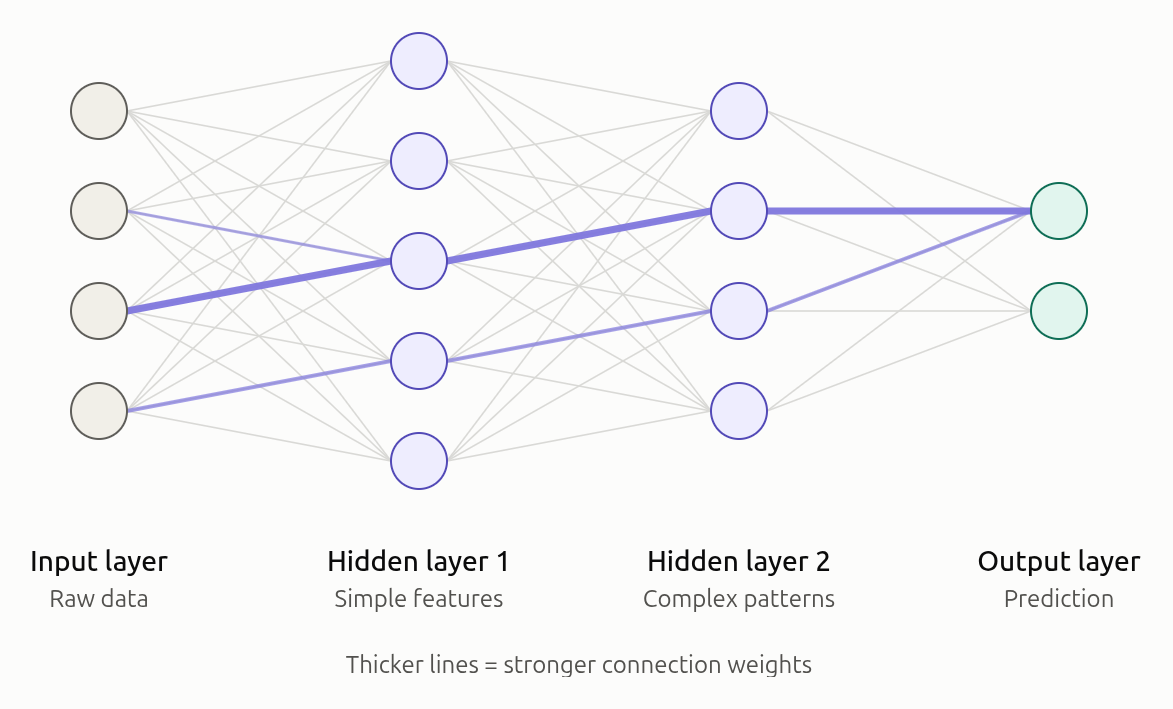

## **Brief Historical Overview**

### The McCulloch–Pitts Neuron (1943)


In 1943, the neurophysiologist **Warren McCulloch** and the young logician **Walter Pitts** published the paper *"A Logical Calculus of the Ideas Immanent in Nervous Activity"* in the *Bulletin of Mathematical Biophysics*. It is widely regarded as the first mathematical model of an artificial neuron.

Their key observation was that a biological neuron is **all-or-none**: at any moment it either fires or it does not. This allowed them to describe neurons using binary values and the language of logic. They showed that networks of such simple units can compute logical propositions, and they argued that, with feedback loops acting as memory, such networks are connected to the computational power of Turing machines.

The paper influenced early computer science and cybernetics. John von Neumann cited it in his 1945 report on the EDVAC computer design, where he used neuron-like notation for logical circuits.

One important feature of the original model: its connections and thresholds are **chosen by hand**. The model does not learn from data.

**The model**

The neuron receives binary inputs (0 or 1). *Excitatory* inputs push the neuron towards firing. An *inhibitory* input acts as an absolute veto.

**Step 1: aggregation.** The neuron adds up its excitatory inputs x₁, …, xₙ:

$$
g(x_1, \dots, x_n) = \sum_{i=1}^{n} x_i, \qquad x_i \in \{0, 1\}
$$

**Step 2: threshold activation.** The neuron fires if the sum reaches the threshold θ:

$$
y = f(g) =
\begin{cases}
1, & g \ge \theta \\
0, & g < \theta
\end{cases}
$$

**Inhibition.** If any inhibitory input s₁, …, sₘ is active, the neuron is silenced:

$$
y =
\begin{cases}
1, & \text{if } \displaystyle\sum_{i=1}^{n} x_i \ge \theta \ \text{ and } \ \displaystyle\sum_{j=1}^{m} s_j = 0 \\
0, & \text{otherwise}
\end{cases}
$$


### Logic gates from a single neuron

By choosing the threshold, one neuron can act as a basic logic gate:

$$
\text{AND:} \quad y = 1 \iff x_1 + x_2 \ge 2 \qquad (\theta = 2)
$$

$$
\text{OR:} \quad y = 1 \iff x_1 + x_2 \ge 1 \qquad (\theta = 1)
$$

$$
\text{NOT:} \quad y = 1 \iff s = 0 \qquad (\theta = 0, \ s \text{ is inhibitory})
$$

| x₁ | x₂ | Σ | AND (θ = 2) | OR (θ = 1) |
|----|----|---|-------------|------------|
| 0  | 0  | 0 | 0           | 0          |
| 0  | 1  | 1 | 0           | 1          |
| 1  | 0  | 1 | 0           | 1          |
| 1  | 1  | 2 | 1           | 1          |

Since AND, OR and NOT are enough to build any logical expression, networks of these neurons can compute any Boolean function.


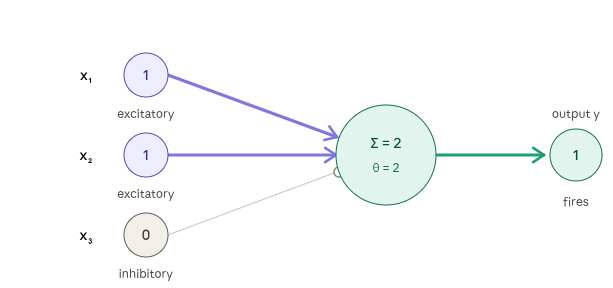

### Rosenblatt's Perceptron (1957–1958)


In the late 1950s, Frank Rosenblatt, a researcher at the Cornell Aeronautical Laboratory, proposed the **perceptron**, described in his 1958 paper *"The Perceptron: A Probabilistic Model for Information Storage and Organization in the Brain"*.

The McCulloch-Pitts neuron had fixed weights that were set by hand, and its inputs were binary (0 or 1). Rosenblatt's key idea was a neuron that **learns its weights from examples**, and whose inputs can be **arbitrary real numbers**, such as the brightness of a pixel. Only the output is binary.

His goal was pattern recognition. The hardware **Mark I Perceptron** looked at images through a grid of 20×20 photocells, with its weights stored in potentiometers adjusted by electric motors. It learned to recognise simple printed characters, such as letters of the alphabet.

In the early 1960s the **perceptron convergence theorem** was proved: if the two classes can be separated by a straight line (or a hyperplane), the learning rule finds the correct weights in a finite number of steps.

**The model**

The neuron receives n real-valued inputs $x_i$ (they are not restricted to 0 and 1). It computes a weighted sum of its inputs plus a bias $b$:

$$
z = \sum_{i=1}^{n} w_i x_i + b
$$

and applies a step function, so the output is binary:

$$
\hat{y} =
\begin{cases}
+1, & z \ge 0 \\
-1, & z < 0
\end{cases}
$$

**The learning rule**

For each training example $(x, t)$, where the correct answer $t$ is either −1 or +1:

- if ŷ = t, nothing changes;
- if ŷ ≠ t, the weights and the bias are updated (η is the learning rate):

$$
w_i \leftarrow w_i + \eta \, t \, x_i, \qquad b \leftarrow b + \eta \, t
$$

If $t = +1$, the weights are pushed up; if $t = −1$, they are pushed down. Because inputs are real-valued, each weight changes in proportion to its input $x_i$: the larger the input, the larger the correction. In both cases the same input is classified better next time.

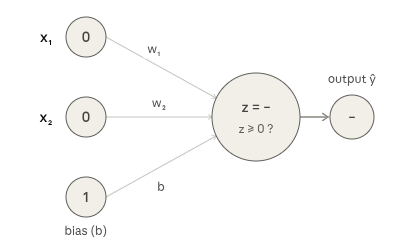

#### The Mark I Perceptron

The **Mark I Perceptron** was a machine built at the Cornell Aeronautical Laboratory around 1960 to implement Rosenblatt's idea in hardware. It had three layers: a "retina" of 400 photocells (a 20×20 grid), 512 association units, and 8 response units. The connections from the photocells to the association units were random and fixed; only the weights of the connections to the response units were adjusted, by electric motors turning potentiometers. By being shown examples and corrected whenever it made a mistake, the machine learned to recognise simple printed characters, such as letters of the alphabet.

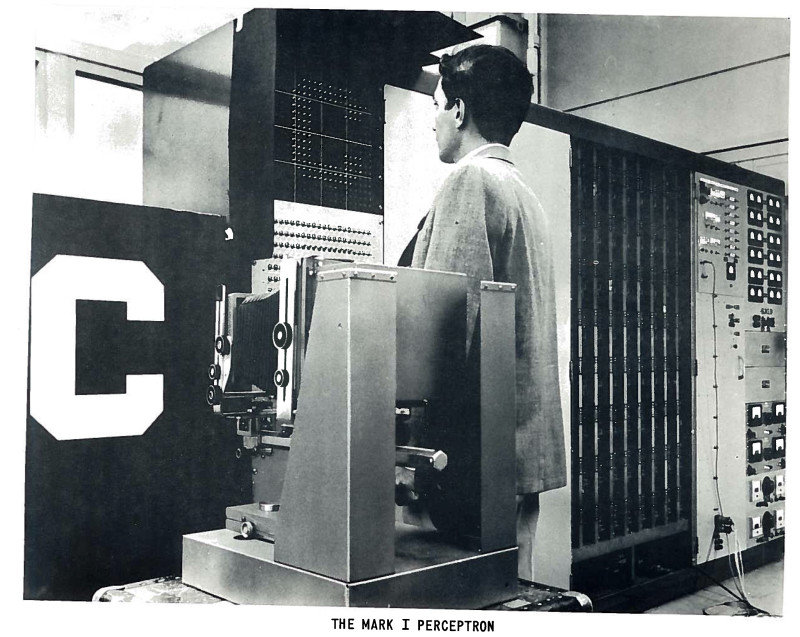

## **Geometrical View of Perceptron**
*(This section is fully based on the book Why Machines Learn: The Elegant Math Behind Modern AI by Anil Ananthaswamy)*

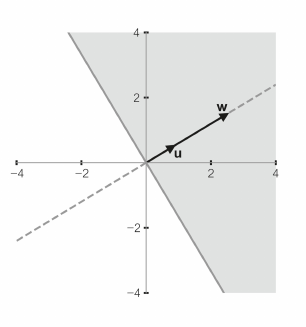

Take the weight vector $w = (2.5, 1.5)$ and the unit vector $u$ that points in the same direction; both lie along the dashed line. Now draw a solid line at right angles to that direction. This line splits the plane into two regions, one shaded and one unshaded. To describe such a dividing boundary, it is enough to know the direction of $w$ (or, equivalently, of $u$), because the boundary is simply the line perpendicular to it. In a 2D space this boundary is a line, in 3D it is a plane, and in higher dimensions it is called a hyperplane.

The perceptron learning algorithm looks for exactly this kind of hyperplane, one that separates the space into two parts. What the perceptron actually learns is a set of weights. Together they form the vector $w$, which is always perpendicular to the hyperplane. When the weights change, $w$ changes direction, and the hyperplane turns with it, staying perpendicular to $w$. The same holds for the unit vector $u$. So saying that the perceptron finds the right weights is the same as saying that it finds the right dividing hyperplane.

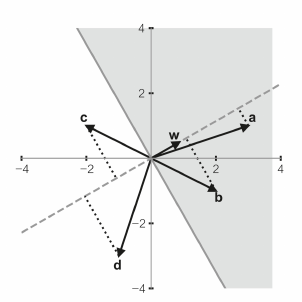

Now consider data points that fall either inside or outside the shaded region. Each point $(x_1, x_2)$ can also be treated as a vector. The weighted sum then turns out to be a dot product of the point's vector $x$ with the weight vector $w$:

$$
w_1 x_1 + w_2 x_2 = \mathbf{w} \cdot \mathbf{x}
$$

If a point lies exactly on the hyperplane (in 2D, simply on the dividing line), its vector $x$ is perpendicular to $w$, so the dot product is zero.

The figure above shows the dot products of several data points with the weight vector. To keep the math simple we use a weight vector of unit length. This changes nothing conceptually. We begin with the vector a, which corresponds to the point $(3, 1)$.

Since $w$ has unit length, its dot product with a equals the projection of a onto the dashed line. The place where a lands on this line, which is perpendicular to the hyperplane, tells us how far the point (3, 1) is from the hyperplane.

The dot product of each vector with $w$ tells us two things about it. Its magnitude shows how far the point is from the hyperplane, and its sign shows which side of the hyperplane the point is on: a positive value means one side, a negative value means the other. In this example, points $a$ and $b$ are linearly separable from points $c$ and $d$. Points in the gray shaded region belong to the class $y = 1$, while points in the unshaded region, as well as points exactly on the dividing line, belong to the class $y = −1$.

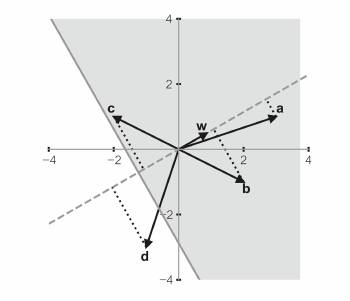

In this picture, we assume $d$ is the sample from another class. This means, the perceptron can find *any* separating line, if data samples are linearly separable.

## **The End Of The First Neural Networks Optimism**

In 1969, Marvin Minsky and Seymour Papert published the book *Perceptrons*, a rigorous analysis of what a single perceptron can and cannot compute. Their best-known example is the **XOR** (exclusive OR) function, which outputs 1 when exactly one of its two inputs is 1. If we plot the four possible inputs, the two points with output 1 lie on one diagonal of the square and the two points with output 0 on the other, so no straight line can separate them. A perceptron's decision boundary is always a single line (or hyperplane), so it can never learn XOR, and the authors showed the same for other simple problems. They also doubted that adding more layers would help, and at the time nobody knew how to train such networks. Together with the huge promises made in the previous decade, this led to a sharp drop in interest and funding for neural networks during the 1970s. Historians stress that other factors also played a role, but the book became the symbol of this turn. The field revived in the 1980s, when backpropagation made it possible to train multi-layer networks, which solve XOR easily.

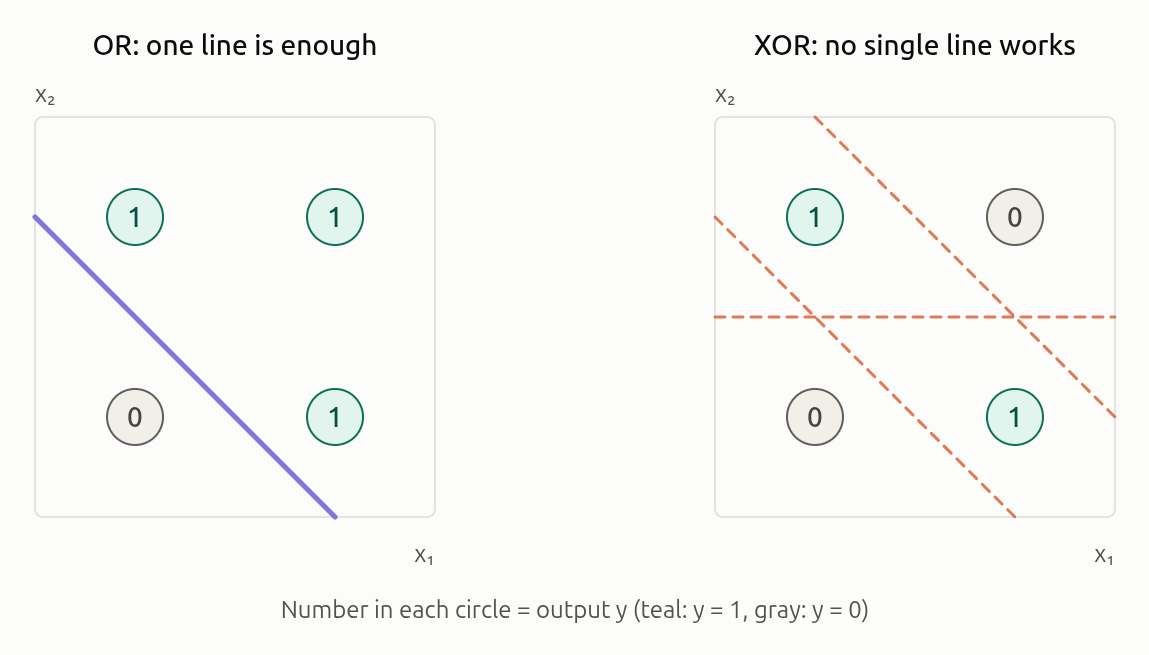

## **The Artificial Neuron and The Activation Function**

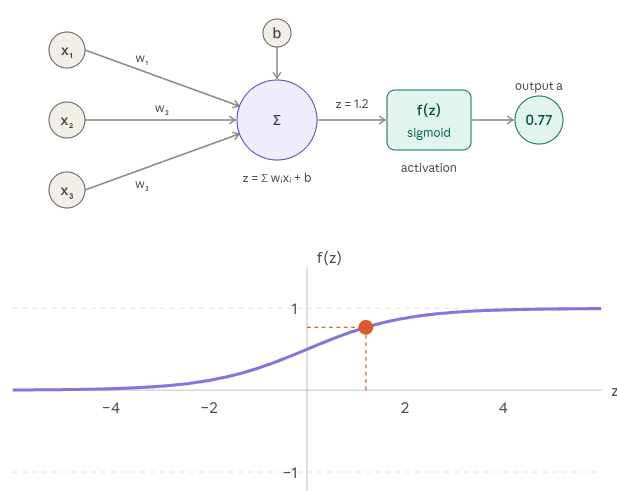

An artificial neuron works in two steps. First it combines its inputs into a single number $z$, using weights $w$ and a bias $b$:

$$
z = \sum_{i=1}^{n} w_i x_i + b = \mathbf{w} \cdot \mathbf{x} + b
$$

Then it passes z through an **activation function** f to produce the output:

$$
a = f(z)
$$

The perceptron is the special case where $f$ is the step function. Modern networks use smooth functions instead. The most common ones are:

$$
\text{step}(z) =
\begin{cases}
1, & z \ge 0 \\
0, & z < 0
\end{cases}
\qquad
\sigma(z) = \frac{1}{1 + e^{-z}}
$$

$$
\tanh(z) = \frac{e^{z} - e^{-z}}{e^{z} + e^{-z}}
\qquad
\text{ReLU}(z) = \max(0, z)
$$

### Why do we need an activation function?

**1. Without it, depth is useless.** A neuron without an activation function computes a purely linear function of its inputs. If we stack two such layers, the result is again a single linear layer:

$$
\mathbf{W}_2 (\mathbf{W}_1 \mathbf{x} + \mathbf{b}_1) + \mathbf{b}_2
= (\mathbf{W}_2 \mathbf{W}_1)\,\mathbf{x} + (\mathbf{W}_2 \mathbf{b}_1 + \mathbf{b}_2)
$$

No matter how many layers we add, the network can only draw a straight line (hyperplane) between classes. A nonlinear activation between the layers is what lets a network represent more complex shapes.

**2. It makes training possible.** The step function has a zero slope everywhere except at $z = 0$, where it is undefined, so a small change in a weight gives no signal about how to improve. Smooth functions such as sigmoid and tanh (and ReLU, almost everywhere) have useful slopes, so we can train the network with gradient descent.

**3. It shapes the output.** Sigmoid squeezes the output into the range (0, 1), which is convenient when the output is interpreted as a probability.

**Note that a nonlinearity alone does not make a *single* neuron more useful: its decision boundary is still a straight line! The real solution comes from combining many neurons into layers.**

### Examples of Activation Functions

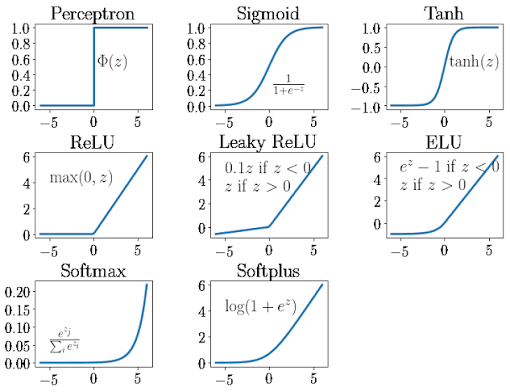

## **A Single Neuron Is Logistic Regression**

We already know logistic regression and gradient descent, and this is exactly what a single neuron with a sigmoid activation does. The neuron computes

$$
z = \mathbf{w} \cdot \mathbf{x} + b, \qquad \hat{y} = \sigma(z) = \frac{1}{1 + e^{-z}}
$$

which is the logistic regression model: ŷ is the predicted probability of class 1.

It is trained in the same way. We measure the error with the binary cross-entropy loss,

$$
L = -\big[\, y \log \hat{y} + (1 - y) \log (1 - \hat{y}) \,\big]
$$

and update the parameters by gradient descent (η is the learning rate):

$$
w_i \leftarrow w_i - \eta \, \frac{\partial L}{\partial w_i}, \qquad b \leftarrow b - \eta \, \frac{\partial L}{\partial b}
$$

For the sigmoid combined with cross-entropy, the gradients turn out to be very simple:

$$
\frac{\partial L}{\partial w_i} = (\hat{y} - y)\, x_i, \qquad \frac{\partial L}{\partial b} = \hat{y} - y
$$

Notice that the update is again "error × input", just like in the perceptron. The difference is that the error $\hat{y} − y$ is now a smooth number instead of a sudden jump, so it tells us not only *whether* the neuron is wrong, but also *by how much*.

## **A Hidden Layer Solves XOR (forward pass)**

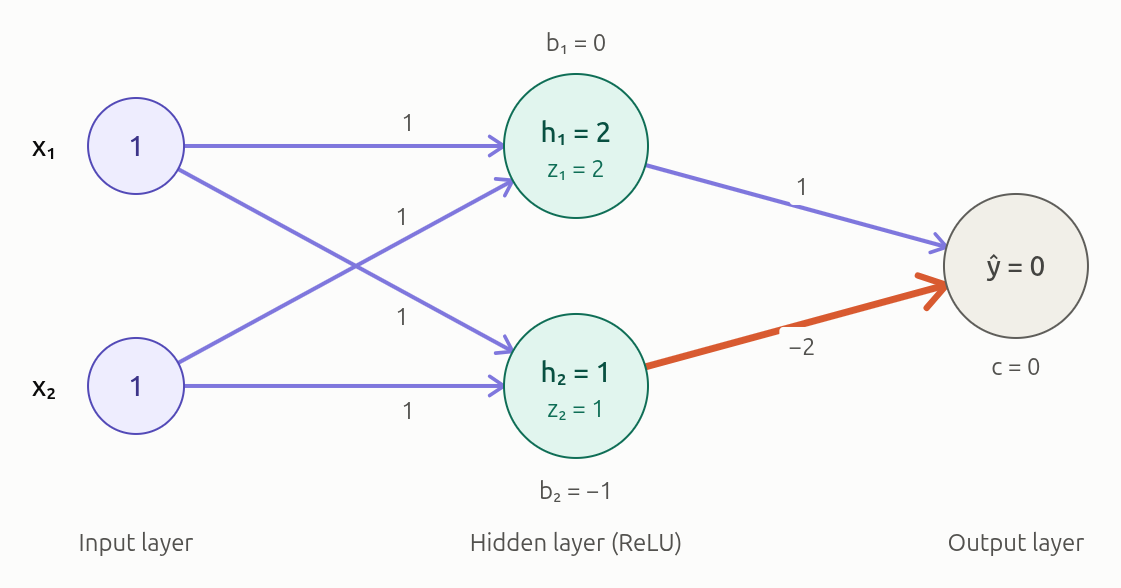

A single neuron draws one straight line, and XOR cannot be separated by one line. The idea is to first **transform the inputs with a hidden layer**, and only then separate the transformed points with an output neuron.

Our network has 2 inputs, 2 hidden neurons with the ReLU activation, ReLU(z) = max(0, z), and 1 output neuron. Computing the output from the input, layer by layer, is called the **forward pass**.

Here we assume that we already know suitable weights (for example, from a network that has already been trained). How a network finds such weights on its own is the topic of backpropagation.

### Step 1: the formulas

The hidden layer takes the input vector x = (x₁, x₂), computes two weighted sums z₁ and z₂, and applies ReLU:

$$
\mathbf{z} = \mathbf{W} \mathbf{x} + \mathbf{b}, \qquad \mathbf{h} = \text{ReLU}(\mathbf{z})
$$

The output neuron combines the hidden values h₁ and h₂:

$$
\hat{y} = \mathbf{v} \cdot \mathbf{h} + c
$$

Here are the known parameters:

$$
\mathbf{W} = \begin{pmatrix} 1 & 1 \\ 1 & 1 \end{pmatrix}, \quad
\mathbf{b} = \begin{pmatrix} 0 \\ -1 \end{pmatrix}, \quad
\mathbf{v} = \begin{pmatrix} 1 \\ -2 \end{pmatrix}, \quad
c = 0
$$

Written neuron by neuron, this means:

$$
z_1 = x_1 + x_2 + 0, \qquad z_2 = x_1 + x_2 - 1, \qquad h_1 = \text{ReLU}(z_1), \qquad h_2 = \text{ReLU}(z_2)
$$

$$
\hat{y} = 1 \cdot h_1 - 2 \cdot h_2 + 0
$$

### Step 2: computing all four inputs

**Input (0, 0), target 0:**

$$
\begin{aligned}
z_1 &= 0 + 0 + 0 = 0, & h_1 &= \text{ReLU}(0) = 0 \\
z_2 &= 0 + 0 - 1 = -1, & h_2 &= \text{ReLU}(-1) = 0 \\
\hat{y} &= 1 \cdot 0 - 2 \cdot 0 = 0
\end{aligned}
$$

**Input (0, 1), target 1:**

$$
\begin{aligned}
z_1 &= 0 + 1 + 0 = 1, & h_1 &= \text{ReLU}(1) = 1 \\
z_2 &= 0 + 1 - 1 = 0, & h_2 &= \text{ReLU}(0) = 0 \\
\hat{y} &= 1 \cdot 1 - 2 \cdot 0 = 1
\end{aligned}
$$

**Input (1, 0), target 1:**

$$
\begin{aligned}
z_1 &= 1 + 0 + 0 = 1, & h_1 &= \text{ReLU}(1) = 1 \\
z_2 &= 1 + 0 - 1 = 0, & h_2 &= \text{ReLU}(0) = 0 \\
\hat{y} &= 1 \cdot 1 - 2 \cdot 0 = 1
\end{aligned}
$$

**Input (1, 1), target 0:**

$$
\begin{aligned}
z_1 &= 1 + 1 + 0 = 2, & h_1 &= \text{ReLU}(2) = 2 \\
z_2 &= 1 + 1 - 1 = 1, & h_2 &= \text{ReLU}(1) = 1 \\
\hat{y} &= 1 \cdot 2 - 2 \cdot 1 = 0
\end{aligned}
$$

### Step 3: summary

| x₁ | x₂ | z₁ | h₁ | z₂ | h₂ | ŷ | target |
|----|----|----|----|----|----|---|--------|
| 0  | 0  | 0  | 0  | −1 | 0  | 0 | 0      |
| 0  | 1  | 1  | 1  | 0  | 0  | 1 | 1      |
| 1  | 0  | 1  | 1  | 0  | 0  | 1 | 1      |
| 1  | 1  | 2  | 2  | 1  | 1  | 0 | 0      |

The network outputs exactly the XOR truth table. (In a real classifier we usually add a sigmoid at the output and predict class 1 when the output is at least 0.5. We skip it here to keep the numbers exact.)

### What if we remove ReLU?

Without the activation function, h₁ = z₁ and h₂ = z₂, and the whole network collapses into a single linear function:

$$
\hat{y} = (x_1 + x_2) - 2(x_1 + x_2 - 1) = 2 - x_1 - x_2
$$

This gives 2, 1, 1, 0 for our four inputs, which is **not** XOR. The nonlinearity is what makes the hidden layer useful.

## **Forward Pass: The General Case**


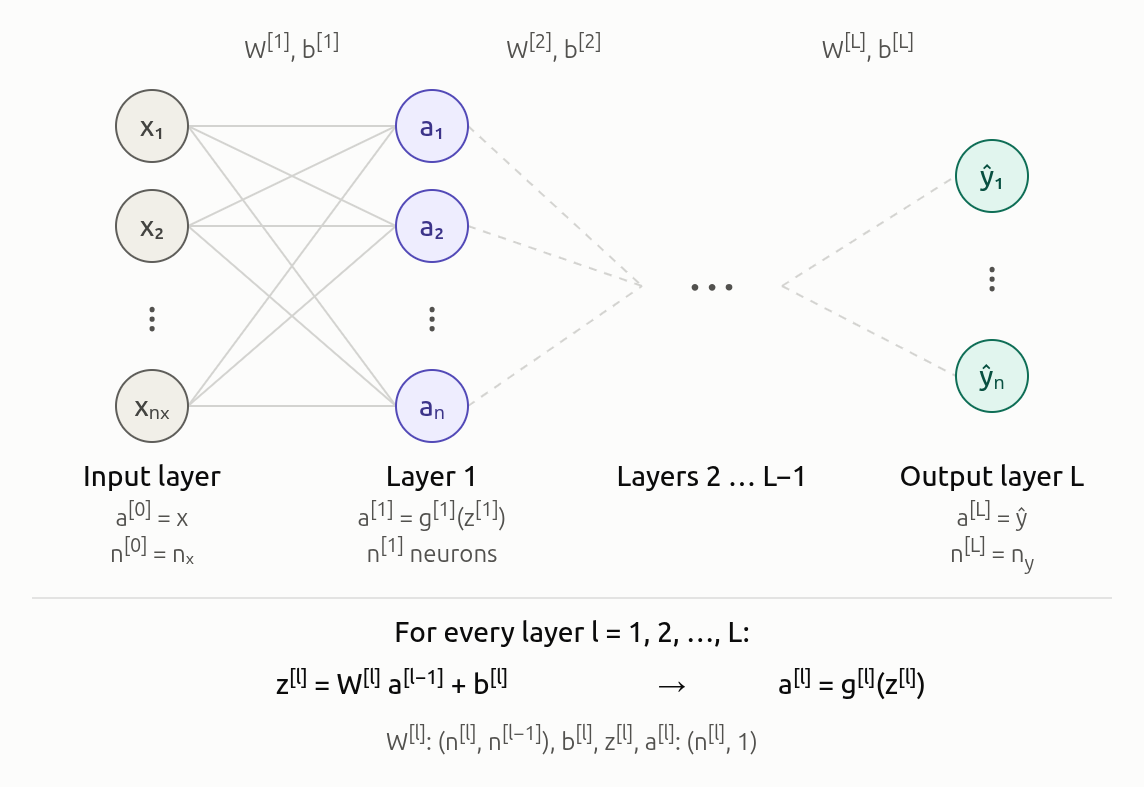

A network with $L$ layers computes its output by repeating the same two steps, layer by layer. This section writes the forward pass in matrix-vector form for any number of inputs, outputs and layers.

### Notation

$$
\begin{aligned}
L &: \text{number of layers (the input is not counted)} \\
n^{[l]} &: \text{number of neurons in layer } l \\
n^{[0]} = n_x &: \text{number of inputs} \\
n^{[L]} = n_y &: \text{number of outputs} \\
\mathbf{W}^{[l]},\ \mathbf{b}^{[l]} &: \text{weights and biases of layer } l \\
g^{[l]} &: \text{activation function of layer } l \\
\mathbf{z}^{[l]},\ \mathbf{a}^{[l]} &: \text{pre-activation and activation of layer } l
\end{aligned}
$$

The input vector is treated as the "activation of layer 0":

$$
\mathbf{a}^{[0]} = \mathbf{x}
$$

### One neuron

Neuron $j$ in layer $l$ takes all activations of the previous layer, forms a weighted sum with its own weight vector and bias, and applies the activation function:

$$
z^{[l]}_j = \mathbf{w}^{[l]T}_j \, \mathbf{a}^{[l-1]} + b^{[l]}_j, \qquad a^{[l]}_j = g^{[l]}\big(z^{[l]}_j\big)
$$

### The whole layer

To compute all neurons of the layer at once, stack their weight vectors as the rows of a matrix:

$$
\mathbf{W}^{[l]} =
\begin{pmatrix}
\mathbf{w}^{[l]T}_1 \\
\mathbf{w}^{[l]T}_2 \\
\vdots \\
\mathbf{w}^{[l]T}_{n^{[l]}}
\end{pmatrix}
$$

Then the entire layer is computed by two formulas:

$$
\mathbf{z}^{[l]} = \mathbf{W}^{[l]} \mathbf{a}^{[l-1]} + \mathbf{b}^{[l]}
$$

$$
\mathbf{a}^{[l]} = g^{[l]}\big(\mathbf{z}^{[l]}\big)
$$

The activation function $g$ acts on each element of the vector separately. The shapes of the objects are:

$$
\mathbf{W}^{[l]} : \big(n^{[l]},\, n^{[l-1]}\big), \qquad
\mathbf{b}^{[l]} : \big(n^{[l]},\, 1\big), \qquad
\mathbf{z}^{[l]},\ \mathbf{a}^{[l]} : \big(n^{[l]},\, 1\big)
$$


### The full forward pass

Start from the input and apply the layer formulas for $l = 1, 2, …, L$. The output of the last layer is the prediction of the network:

```
a[0] = x
for l = 1, 2, ..., L:
    z[l] = W[l] a[l-1] + b[l]
    a[l] = g[l](z[l])
y_hat = a[L]
```

$$
\hat{\mathbf{y}} = \mathbf{a}^{[L]}
$$

We keep the values of $z$ and a for every layer, because backpropagation will need them later. The activation of the output layer depends on the task: sigmoid for binary classification, softmax for several classes, and the identity function for regression.

The final layer is special because its activation function $g^{[L]}$ must transform the raw scores (logits) $\mathbf{z}^{[L]}$ into a meaningful prediction. Unlike hidden layers, it does not add non-linearity for feature extraction; its sole purpose is to format the output for the specific task:

* **Binary classification:** We use the **sigmoid** function, $\sigma(z) = \frac{1}{1 + e^{-z}}$. It squashes the output of a single neuron ($n^{[L]} = 1$) into the range $(0, 1)$, allowing us to interpret it as the probability of the positive class.
* **Multi-class classification:** We use the **softmax** function. It takes the outputs of $C$ neurons ($n^{[L]} = C$) and normalizes them into a valid probability distribution, where all values are strictly positive and sum exactly to 1.
* **Regression:** We use the **identity** (linear) function, $g(z) = z$. Since we are predicting continuous, unbounded values (like house prices or temperatures), we do not restrict the output range at all.

In all cases, the final prediction is simply $\hat{\mathbf{y}} = \mathbf{a}^{[L]} = g^{[L]}(\mathbf{z}^{[L]})$.


### Many examples at once

In practice we process m training examples simultaneously. Put the input vectors side by side as the columns of a matrix:

$$
\mathbf{X} =
\begin{pmatrix}
\mathbf{x}^{(1)} & \mathbf{x}^{(2)} & \cdots & \mathbf{x}^{(m)}
\end{pmatrix}
\in \mathbb{R}^{n_x \times m}
$$

The formulas keep the same form, with capital letters for matrices whose columns correspond to the examples:

$$
\mathbf{A}^{[0]} = \mathbf{X}
$$

$$
\mathbf{Z}^{[l]} = \mathbf{W}^{[l]} \mathbf{A}^{[l-1]} + \mathbf{b}^{[l]}, \qquad
\mathbf{A}^{[l]} = g^{[l]}\big(\mathbf{Z}^{[l]}\big)
$$

$$
\hat{\mathbf{Y}} = \mathbf{A}^{[L]} \in \mathbb{R}^{n_y \times m}
$$

The shapes of $Z$ and $A$ are now $(n^{[l]}, m)$. The bias vector b of shape $(n^{[l]}, 1)$ is added to every column (this is called *broadcasting*), so $W$ and b stay exactly the same for all examples.

## **Random Initial Weights And The Symmetry Problem**

If all the weights in a layer start with the same values (for example, all zeros), every neuron in that layer computes exactly the same thing. I.e., they also receive exactly the same updates, so they stay identical after every training step. A hidden layer with 100 identical neurons is no better than a layer with one. With ReLU and all-zero weights it is even worse: every hidden output is 0, so the network passes no signal at all.

The fix is to initialise the weights with small random numbers, so that every neuron starts out different and can learn to detect something different. The biases can safely start at zero, because the random weights already break the symmetry.

The *scale* of the random numbers matters too. If the weights are too large, the values $z$ grow from layer to layer (and sigmoid or tanh saturate); if they are too small, the signal shrinks to almost nothing.

To solve the scale problem, we use initialization methods that adjust the random weights based on the layer's size ($n_{in}$ = input neurons, $n_{out}$ = output neurons):

* **Xavier (Glorot) Initialization** (best for Sigmoid/Tanh): Keeps variance stable across layers by setting the weight variance to $\sigma^2 = \frac{2}{n_{in} + n_{out}}$.
* **He (Kaiming) Initialization** (best for ReLU): Compensates for ReLU zeroing out negative values by setting the weight variance to $\sigma^2 = \frac{2}{n_{in}}$.

*(Note: Modern frameworks like PyTorch apply these automatically when you create a layer!)*

## **Backpropagation Algorithm: How Neural Networks Learn**

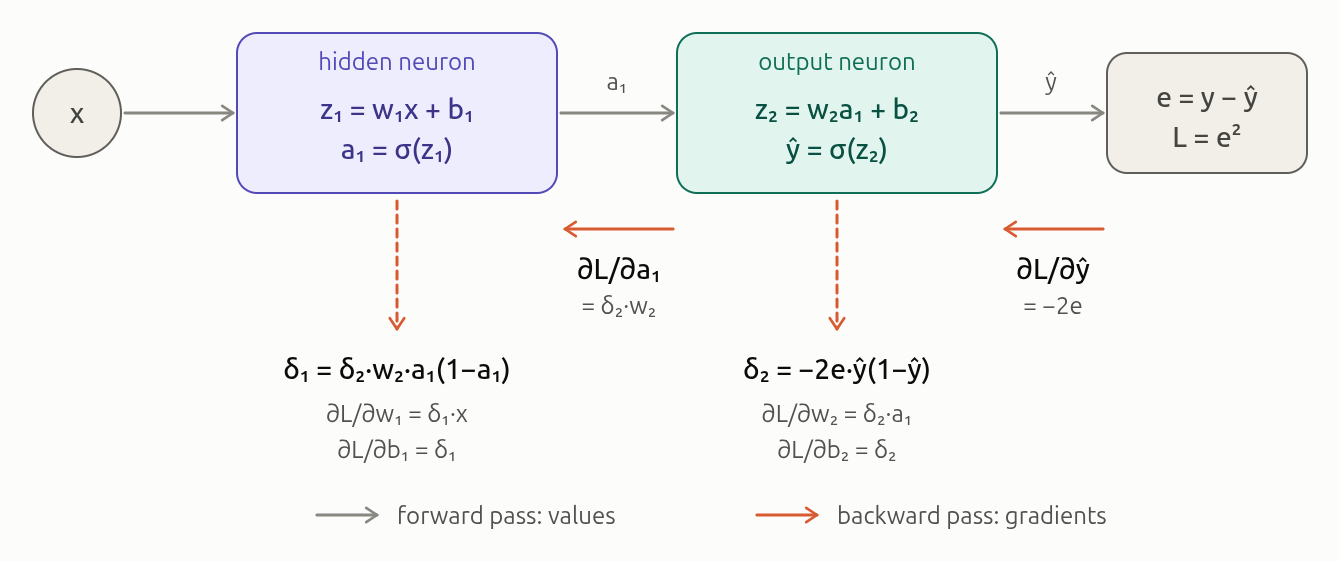

To train a network we need to know how the loss $L$ changes when we change each weight and bias. **Backpropagation** is an efficient way to compute all these derivatives: it applies the chain rule starting from the output and moving backwards, layer by layer, reusing the results already computed.

We use the simplest possible network: one input $x$, one hidden neuron (weight $w_1$, bias $b_1$), and one output neuron (weight $w_2$, bias $b_2$). Both neurons use the sigmoid activation. For one training example $(x, y)$ we measure the error and the loss as

$$
e = y - \hat{y}, \qquad L = e^2
$$

### Step 1: the forward pass

$$
\begin{aligned}
z_1 &= w_1 x + b_1 \\
a_1 &= \sigma(z_1) \\
z_2 &= w_2 a_1 + b_2 \\
\hat{y} &= \sigma(z_2) \\
e &= y - \hat{y} \\
L &= e^2
\end{aligned}
$$

We will need the derivative of the sigmoid:

$$
\sigma'(z) = \frac{e^{-z}}{\left(1 + e^{-z}\right)^2} = \sigma(z)\big(1 - \sigma(z)\big)
$$

so that:

$$
\sigma'(z_2) = \hat{y}\,(1 - \hat{y}), \qquad \sigma'(z_1) = a_1\,(1 - a_1)
$$

### Step 2: the goal

We need four derivatives:

$$
\frac{\partial L}{\partial w_2}, \qquad \frac{\partial L}{\partial b_2}, \qquad \frac{\partial L}{\partial w_1}, \qquad \frac{\partial L}{\partial b_1}
$$

Each of them is found with the chain rule, by multiplying the derivatives along the path from the parameter to the loss. For example:

$$
\frac{\partial L}{\partial w_2}
= \frac{\partial L}{\partial \hat{y}} \cdot \frac{\partial \hat{y}}{\partial z_2} \cdot \frac{\partial z_2}{\partial w_2}
$$

$$
\frac{\partial L}{\partial w_1}
= \frac{\partial L}{\partial \hat{y}} \cdot
  \frac{\partial \hat{y}}{\partial z_2} \cdot
  \frac{\partial z_2}{\partial a_1} \cdot
  \frac{\partial a_1}{\partial z_1} \cdot
  \frac{\partial z_1}{\partial w_1}
$$



### Step 3: the backward pass

We move from the end of the network to the beginning.

**3.1. Derivative of the loss with respect to the output.** Since the loss is the squared error:

$$
\frac{\partial L}{\partial \hat{y}}
= \frac{\partial}{\partial \hat{y}} (y - \hat{y})^2
= -2(y - \hat{y}) = -2e
$$

**3.2. Through the output sigmoid.** The product of the first two factors of the chain is the "error signal" of the output neuron, which we call $\delta_2$:

$$
\delta_2 = \frac{\partial L}{\partial z_2}
= \frac{\partial L}{\partial \hat{y}} \cdot \frac{\partial \hat{y}}{\partial z_2}
= -2e \cdot \hat{y}(1 - \hat{y})
$$

**3.3. Gradients of the output neuron.** The value $z_2$ is linear in the weight and in the bias, so its derivatives are:

$$
\frac{\partial z_2}{\partial w_2} = a_1, \qquad \frac{\partial z_2}{\partial b_2} = 1
$$

Therefore:

$$
\frac{\partial L}{\partial w_2} = \delta_2 \, a_1, \qquad \frac{\partial L}{\partial b_2} = \delta_2
$$

**3.4. Passing the error back to the hidden neuron.** The value $z_2$ depends on the hidden activation $a_1$ through the weight $w_2$:

$$
\frac{\partial z_2}{\partial a_1} = w_2, \qquad
\frac{\partial L}{\partial a_1} = \delta_2 \, w_2
$$

**3.5. Through the hidden sigmoid.** Multiplying by the slope of the hidden sigmoid gives the error signal of the hidden neuron:

$$
\delta_1 = \frac{\partial L}{\partial z_1}
= \frac{\partial L}{\partial a_1} \cdot \frac{\partial a_1}{\partial z_1}
= \delta_2 \, w_2 \cdot a_1(1 - a_1)
$$

**3.6. Gradients of the hidden neuron.** Again, $z_1$ is linear in the weight and in the bias:

$$
\frac{\partial z_1}{\partial w_1} = x, \qquad \frac{\partial z_1}{\partial b_1} = 1
$$

Therefore:

$$
\frac{\partial L}{\partial w_1} = \delta_1 \, x, \qquad \frac{\partial L}{\partial b_1} = \delta_1
$$

Notice the pattern: each error signal $\delta$ is computed from the one that came after it ($\delta_2 \cdot w_2$), multiplied by the slope of the activation function. The gradients of the weights are then "error signal × input of the neuron". This is exactly what repeats, layer after layer, in larger networks.

### Step 4: the update

Each parameter is moved against its gradient ($\eta$ is the learning rate):

$$
w_2 \leftarrow w_2 - \eta \frac{\partial L}{\partial w_2}, \quad
b_2 \leftarrow b_2 - \eta \frac{\partial L}{\partial b_2}, \quad
w_1 \leftarrow w_1 - \eta \frac{\partial L}{\partial w_1}, \quad
b_1 \leftarrow b_1 - \eta \frac{\partial L}{\partial b_1}
$$

### A numerical example

Take the following values:

$$
x = 1, \quad y = 1, \quad w_1 = 0.5, \quad b_1 = 0, \quad w_2 = 2, \quad b_2 = -1, \quad \eta = 1
$$

**Forward pass:**

$$
\begin{aligned}
z_1 &= 0.5 \cdot 1 + 0 = 0.5 \\
a_1 &= \sigma(0.5) \approx 0.6225 \\
z_2 &= 2 \cdot 0.6225 - 1 \approx 0.2449 \\
\hat{y} &= \sigma(0.2449) \approx 0.5609 \\
e &= 1 - 0.5609 = 0.4391 \\
L &= 0.4391^2 \approx 0.1928
\end{aligned}
$$

**Backward pass:**

$$
\begin{aligned}
\frac{\partial L}{\partial \hat{y}} &= -2e = -0.8782 \\
\hat{y}(1 - \hat{y}) &= 0.5609 \cdot 0.4391 \approx 0.2463 \\
\delta_2 &= -0.8782 \cdot 0.2463 \approx -0.2163 \\
\frac{\partial L}{\partial w_2} &= \delta_2 a_1 = -0.2163 \cdot 0.6225 \approx -0.1346 \\
\frac{\partial L}{\partial b_2} &= \delta_2 \approx -0.2163 \\
\frac{\partial L}{\partial a_1} &= \delta_2 w_2 = -0.2163 \cdot 2 = -0.4326 \\
a_1(1 - a_1) &= 0.6225 \cdot 0.3775 \approx 0.2350 \\
\delta_1 &= -0.4326 \cdot 0.2350 \approx -0.1017 \\
\frac{\partial L}{\partial w_1} &= \delta_1 x \approx -0.1017 \\
\frac{\partial L}{\partial b_1} &= \delta_1 \approx -0.1017
\end{aligned}
$$

**Update:**

$$
\begin{aligned}
w_1 &= 0.5 - 1 \cdot (-0.1017) = 0.6017 \\
b_1 &= 0 - 1 \cdot (-0.1017) = 0.1017 \\
w_2 &= 2 - 1 \cdot (-0.1346) = 2.1346 \\
b_2 &= -1 - 1 \cdot (-0.2163) = -0.7837
\end{aligned}
$$

**Check: a new forward pass with the updated parameters:**

$$
z_1 \approx 0.7033, \quad a_1 \approx 0.6689, \quad z_2 \approx 0.6442, \quad \hat{y} \approx 0.6557, \quad L \approx 0.1185
$$

Compared with the first forward pass, the prediction and the loss changed as follows:

$$
\hat{y}: \; 0.5609 \to 0.6557, \qquad L: \; 0.1928 \to 0.1185
$$

The prediction moved towards the target, and the loss decreased. Repeating this procedure many times is the training of the network.

### A remark on the loss function

With the squared error, the error signal of the output neuron contains the factor $\hat{y}(1 - \hat{y})$:

$$
\delta_2 = -2e \cdot \hat{y}(1 - \hat{y})
$$

When the output neuron is confidently wrong, the prediction is close to 0 or 1, this factor is almost zero, and learning becomes very slow. With the cross-entropy loss, which we used for logistic regression, this factor cancels and the error signal becomes simply:

$$
\delta_2 = \hat{y} - y
$$

This is why cross-entropy is the standard choice for sigmoid outputs. We use the squared error here only to keep the derivation simple.

### **Backpropagation: The general Case**

Now we write backpropagation in matrix-vector form for a network with any number of layers and neurons, in the same notation as the general forward pass. The idea is exactly the one from the simplest network: the chain rule applied from the output backwards. Only now every layer is processed with a few matrix operations.

### Notation

Following the forward pass, $\mathbf{W}^{[l]}$, $\mathbf{b}^{[l]}$, $\mathbf{Z}^{[l]}$, $\mathbf{A}^{[l]}$ and $g^{[l]}$ denote the weights, biases, pre-activations, activations and the activation function of layer $l$. We add the following convention: a symbol with the prefix $d$ denotes the derivative of the loss with respect to that quantity:

$$
d\mathbf{A}^{[l]} = \frac{\partial L}{\partial \mathbf{A}^{[l]}}, \qquad
d\mathbf{Z}^{[l]} = \frac{\partial L}{\partial \mathbf{Z}^{[l]}}, \qquad
d\mathbf{W}^{[l]} = \frac{\partial L}{\partial \mathbf{W}^{[l]}}, \qquad
d\mathbf{b}^{[l]} = \frac{\partial L}{\partial \mathbf{b}^{[l]}}
$$

The symbol $\odot$ denotes the element-wise product of two matrices of the same shape. The matrix $d\mathbf{Z}^{[l]}$ is the matrix form of the "error signals" $\delta$ from the previous section.


During the forward pass we store $\mathbf{Z}^{[l]}$ and $\mathbf{A}^{[l]}$ for every layer, since the backward pass uses them.


Let us see why the formulas have the form given below. For a single example, the entries of $\mathbf{z}^{[l]}$ are

$$
z^{[l]}_j = \sum_{k} W^{[l]}_{jk} \, a^{[l-1]}_k + b^{[l]}_j
$$

Suppose we already know the error signals of this layer, $\delta_j = \partial L / \partial z^{[l]}_j$. Then:

$$
\frac{\partial z^{[l]}_j}{\partial W^{[l]}_{jk}} = a^{[l-1]}_k
\quad \Rightarrow \quad
\frac{\partial L}{\partial W^{[l]}_{jk}} = \delta_j \, a^{[l-1]}_k
$$

$$
\frac{\partial z^{[l]}_j}{\partial b^{[l]}_j} = 1
\quad \Rightarrow \quad
\frac{\partial L}{\partial b^{[l]}_j} = \delta_j
$$

The activation $a^{[l-1]}_k$ influences every neuron $j$ of layer $l$, so the contributions are summed:

$$
\frac{\partial z^{[l]}_j}{\partial a^{[l-1]}_k} = W^{[l]}_{jk}
\quad \Rightarrow \quad
\frac{\partial L}{\partial a^{[l-1]}_k} = \sum_{j} W^{[l]}_{jk} \, \delta_j
$$

In matrix form, the first formula is an outer product of the vectors $\boldsymbol{\delta}$ and $\mathbf{a}^{[l-1]}$, and the last one is a product with the transposed weight matrix.

### The formulas for a whole layer

For all $m$ examples at once, the matrices $d\mathbf{Z}^{[l]}$ and $\mathbf{A}^{[l-1]}$ have the examples as columns, and the same operations give:

$$
d\mathbf{W}^{[l]} = \frac{1}{m} \, d\mathbf{Z}^{[l]} \, \mathbf{A}^{[l-1]T}
$$

$$
d\mathbf{b}^{[l]} = \frac{1}{m} \sum_{i=1}^{m} d\mathbf{Z}^{[l](i)}
$$

$$
d\mathbf{A}^{[l-1]} = \mathbf{W}^{[l]T} \, d\mathbf{Z}^{[l]}
$$

$$
d\mathbf{Z}^{[l-1]} = d\mathbf{A}^{[l-1]} \odot g^{[l-1]\prime}\big(\mathbf{Z}^{[l-1]}\big)
$$

The factor $1/m$ appears because the cost is the average of the losses over the $m$ examples, and the gradients of the parameters add up over the examples. In $d\mathbf{b}^{[l]}$ the sum is taken along the columns of $d\mathbf{Z}^{[l]}$ (one column per example).

The shapes match those of the forward pass:

$$
d\mathbf{Z}^{[l]},\ d\mathbf{A}^{[l]} : \big(n^{[l]},\, m\big), \qquad
d\mathbf{W}^{[l]} : \big(n^{[l]},\, n^{[l-1]}\big), \qquad
d\mathbf{b}^{[l]} : \big(n^{[l]},\, 1\big)
$$

A useful check: $d\mathbf{W}^{[l]}$ must have the same shape as $\mathbf{W}^{[l]}$, and $d\mathbf{b}^{[l]}$ the same shape as $\mathbf{b}^{[l]}$. Indeed, $\big(n^{[l]}, m\big)$ times $\big(m, n^{[l-1]}\big)$ gives $\big(n^{[l]}, n^{[l-1]}\big)$.

### The start of the backward pass: the output layer

The backward pass starts at the last layer, and the first step depends on the loss function and on the output activation. Two common cases:

**Squared error with a sigmoid output** (as in our simplest network):

$$
d\mathbf{A}^{[L]} = -2\,\big(\mathbf{Y} - \mathbf{A}^{[L]}\big), \qquad
d\mathbf{Z}^{[L]} = d\mathbf{A}^{[L]} \odot \mathbf{A}^{[L]} \odot \big(1 - \mathbf{A}^{[L]}\big)
$$

**Cross-entropy with a sigmoid output** (binary classification). The factor with the slope of the sigmoid cancels, and we get directly:

$$
d\mathbf{Z}^{[L]} = \mathbf{A}^{[L]} - \mathbf{Y}
$$

### The full backward pass

After the output layer, we go through the layers in the opposite order, $l = L, L-1, \dots, 1$:

```
dZ[L] = (depends on the loss, see above)
for l = L, L-1, ..., 1:
    dW[l] = (1/m) dZ[l] A[l-1]^T
    db[l] = (1/m) sum of the columns of dZ[l]
    if l > 1:
        dA[l-1] = W[l]^T dZ[l]
        dZ[l-1] = dA[l-1] * g'[l-1](Z[l-1])      # element-wise product
```

Note that $\mathbf{A}^{[0]} = \mathbf{X}$, so the first layer uses the input data.

### The update

When the backward pass is finished, gradient descent updates every layer:

$$
\mathbf{W}^{[l]} \leftarrow \mathbf{W}^{[l]} - \eta \, d\mathbf{W}^{[l]}, \qquad
\mathbf{b}^{[l]} \leftarrow \mathbf{b}^{[l]} - \eta \, d\mathbf{b}^{[l]}
$$

Backpropagation itself only computes the gradients $d\mathbf{W}^{[l]}$ and $d\mathbf{b}^{[l]}$; the update step is gradient descent.

## **Backpropagation in Large Language Models**

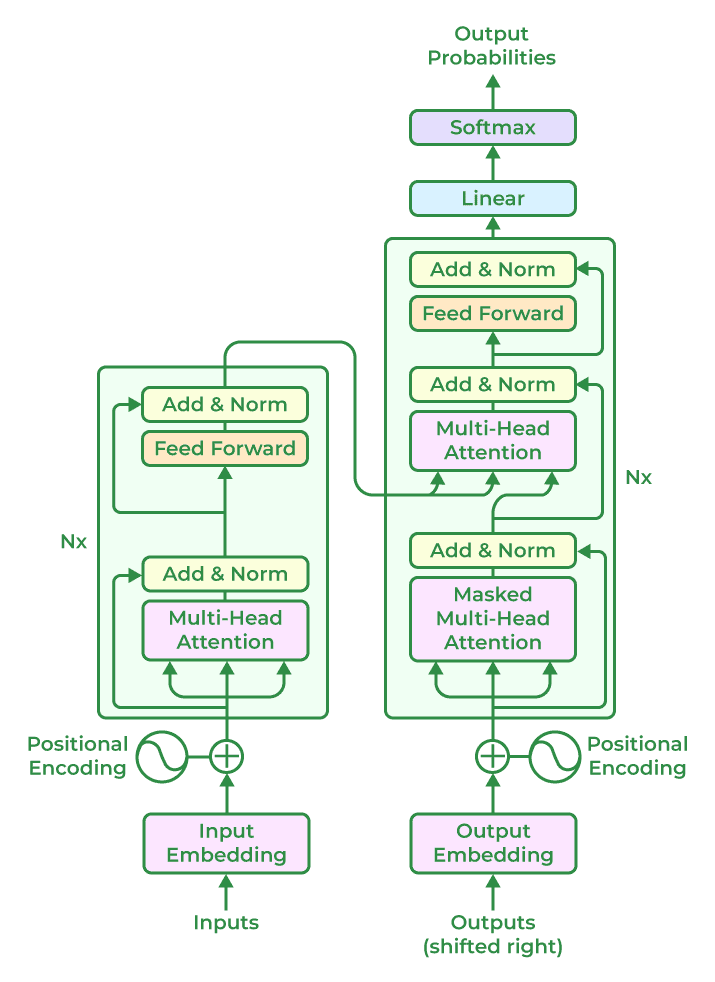

Large language models are trained with exactly the same algorithm. A transformer is a deep neural network, so its gradients are computed by backpropagation, only not by hand: frameworks such as PyTorch and JAX apply the chain rule automatically through every layer. Most of the layers (the projections in the attention mechanism and the fully connected blocks) have the familiar form of a weight matrix times the activations of the previous layer, so the formulas for $dW$ and $dA$ from the previous section apply to them unchanged.

The differences are in the details, not in the idea. The model is trained to predict the next token with the cross-entropy loss, and the output layer uses softmax instead of sigmoid. Just as in logistic regression, the error signal of the output layer turns out to be simple:

$$
d\mathbf{Z}^{[L]} = \hat{\mathbf{y}} - \mathbf{y}
$$

Inside the network, sigmoid is replaced by smoother modern activations such as $GELU$, and residual connections give the gradient a short path back through hundreds of layers, which helps against vanishing gradients. The weights are updated by the $AdamW$ optimizer instead of plain gradient descent, and the computation is spread over thousands of GPUs. But the gradients themselves come from the same chain rule that we applied to a single neuron.

## **Resources**

1. [StatQuest Series](https://youtube.com/playlist?list=PLblh5JKOoLUIxGDQs4LFFD--41Vzf-ME1&si=Ub0LZbNx0ibKRg5p)
2. [JAX library](https://docs.jax.dev/en/latest/101/index.html)
3. [Deep Learning Book](https://www.deeplearningbook.org/)
4. [Understanding Deep Learning](https://udlbook.github.io/udlbook/)
5. [Deep Learning Specialization by Andrew Ng](https://www.youtube.com/watch?v=CS4cs9xVecg&list=PLkDaE6sCZn6Ec-XTbcX1uRg2_u4xOEky0)
6. Andrew W. Trask. Grokking Deep Learning
7. Daniel Godoy. Deep Learning with PyTorch Step-by-Step A Beginner's Guide Revised for PyTorch 2.x